In [15]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


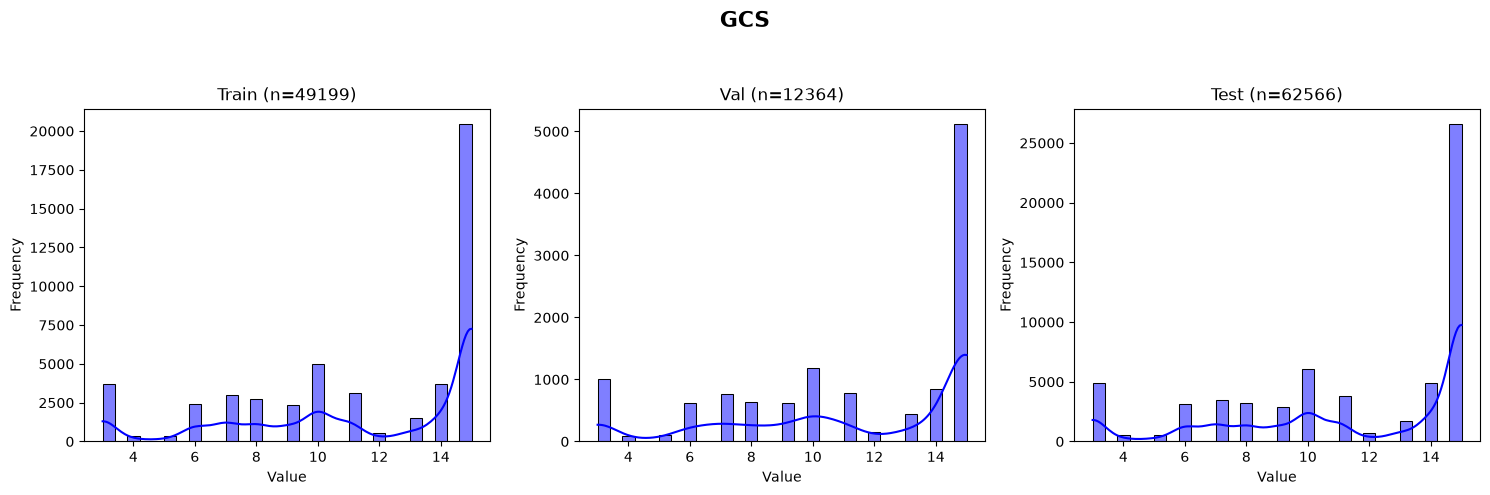

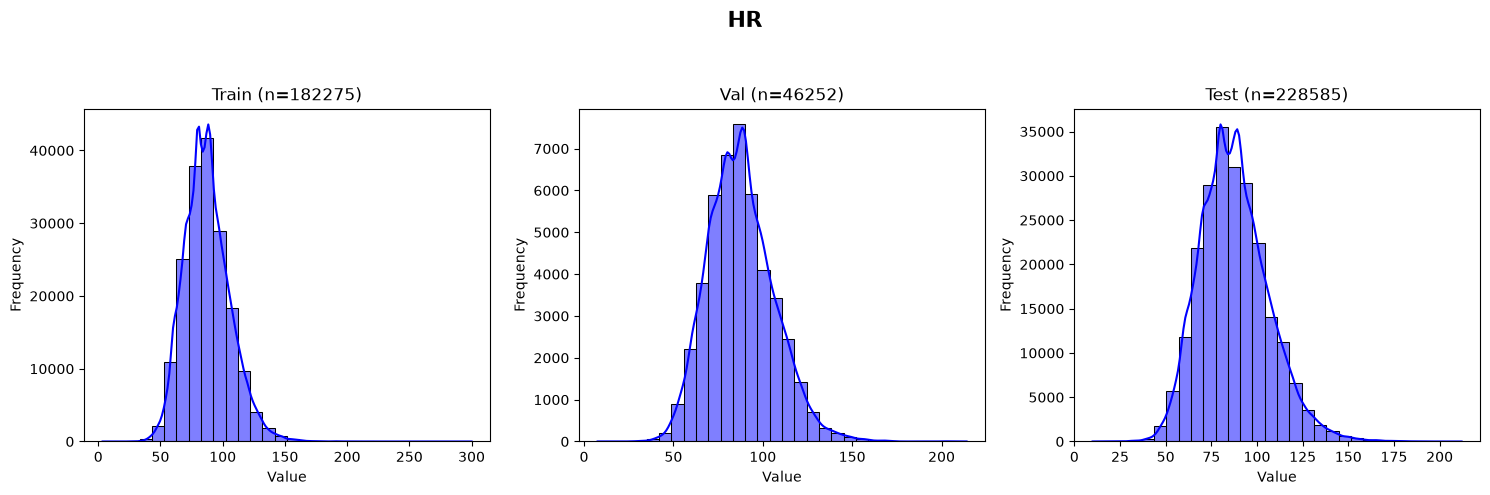

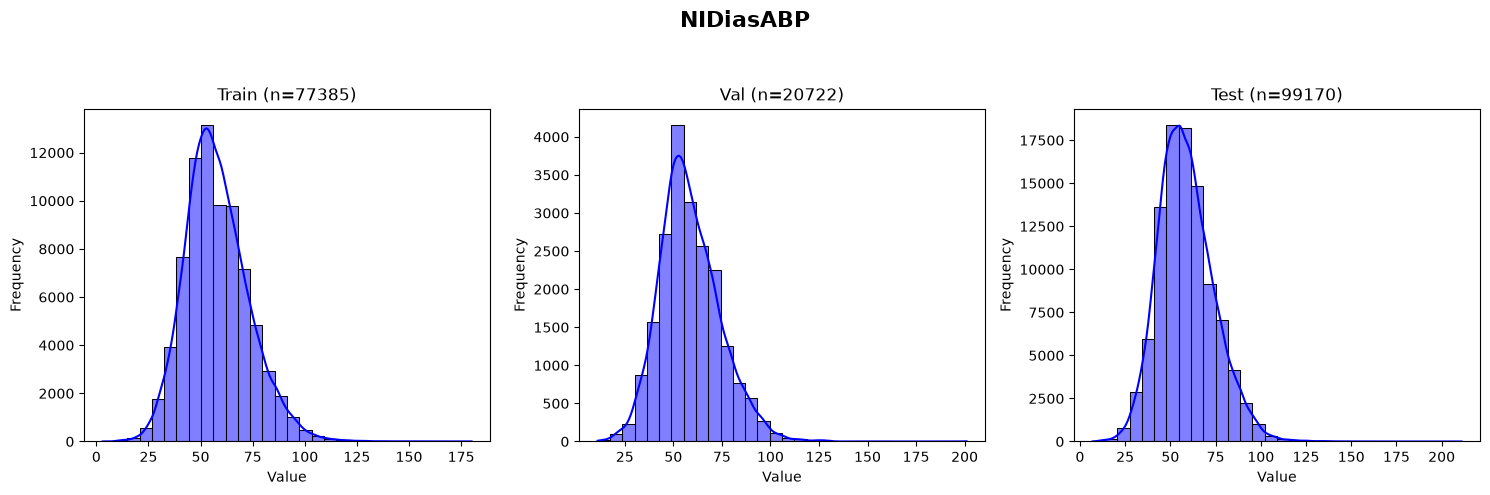

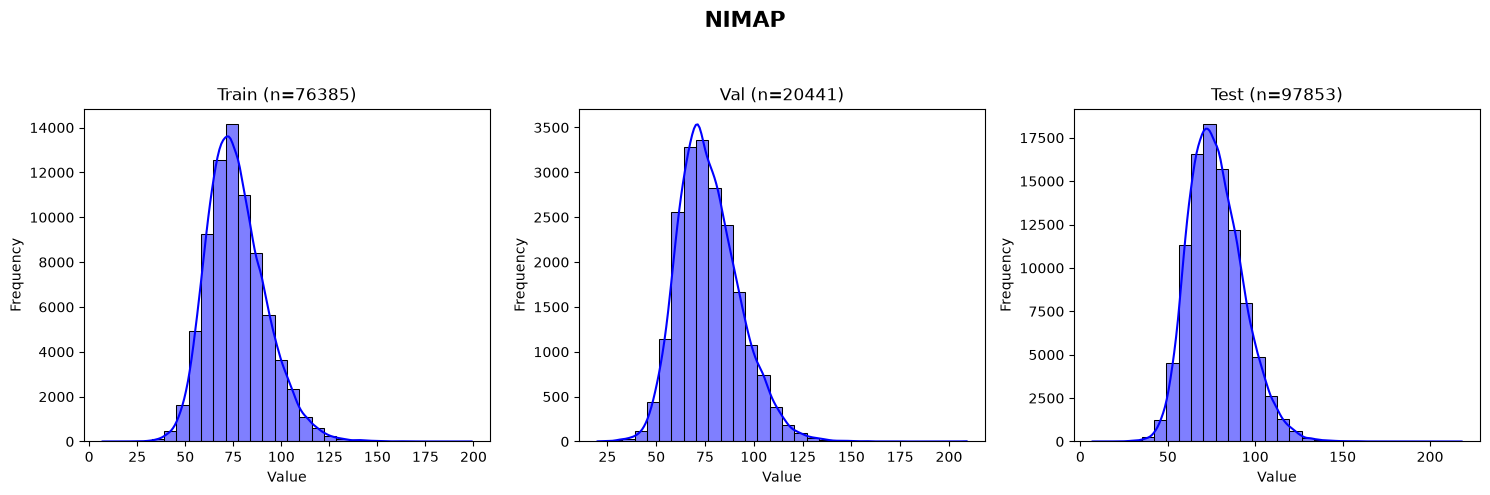

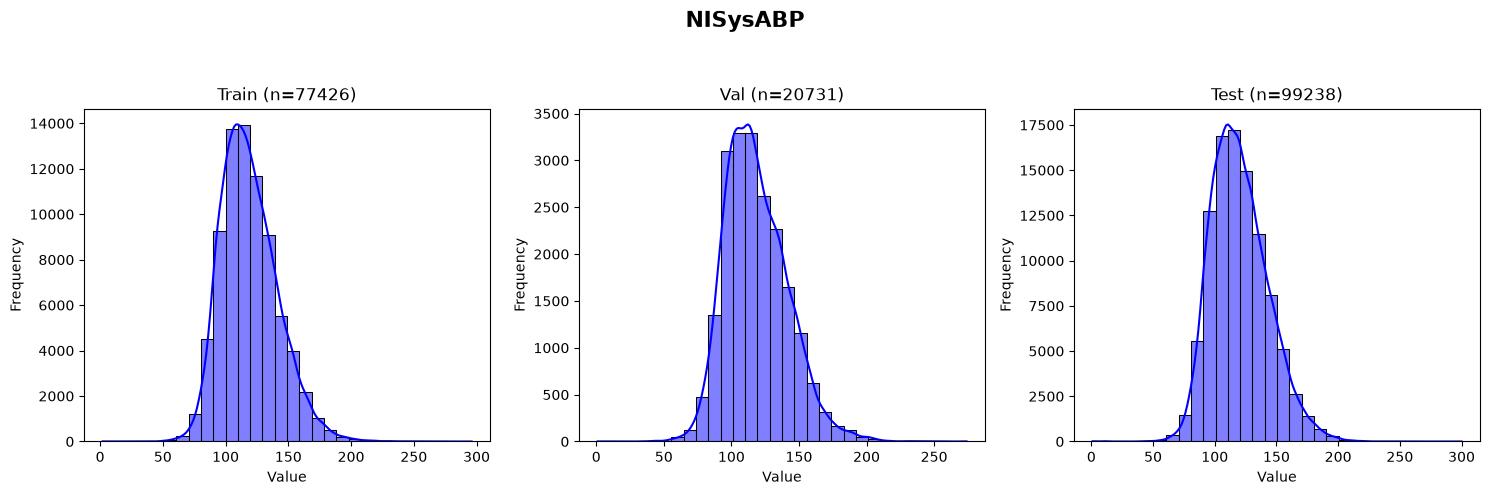

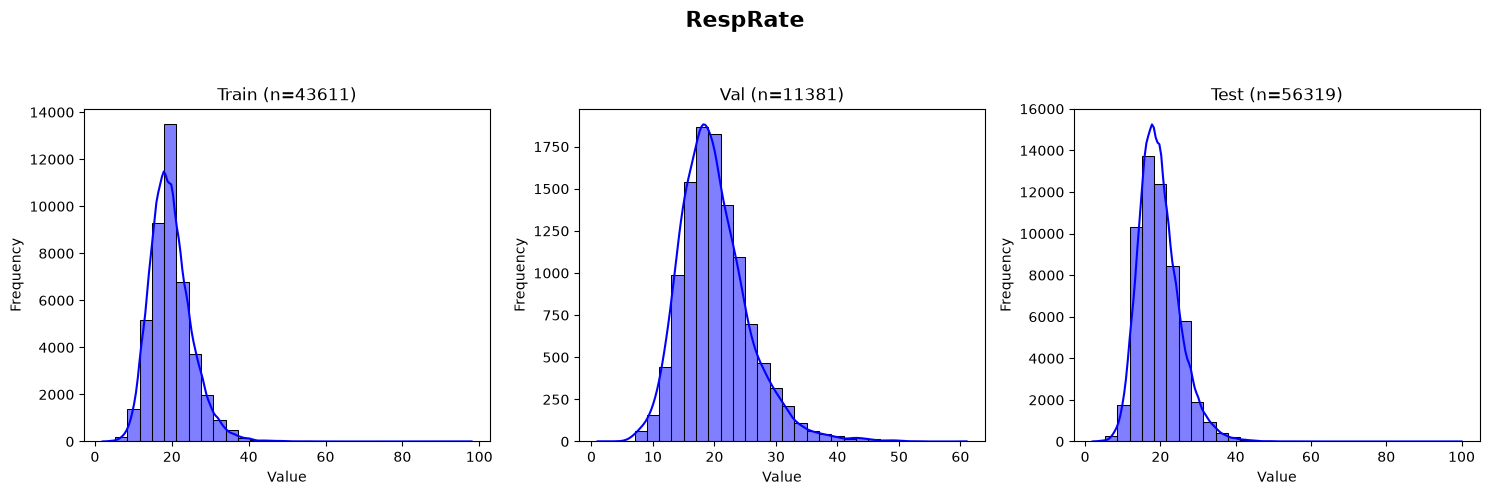

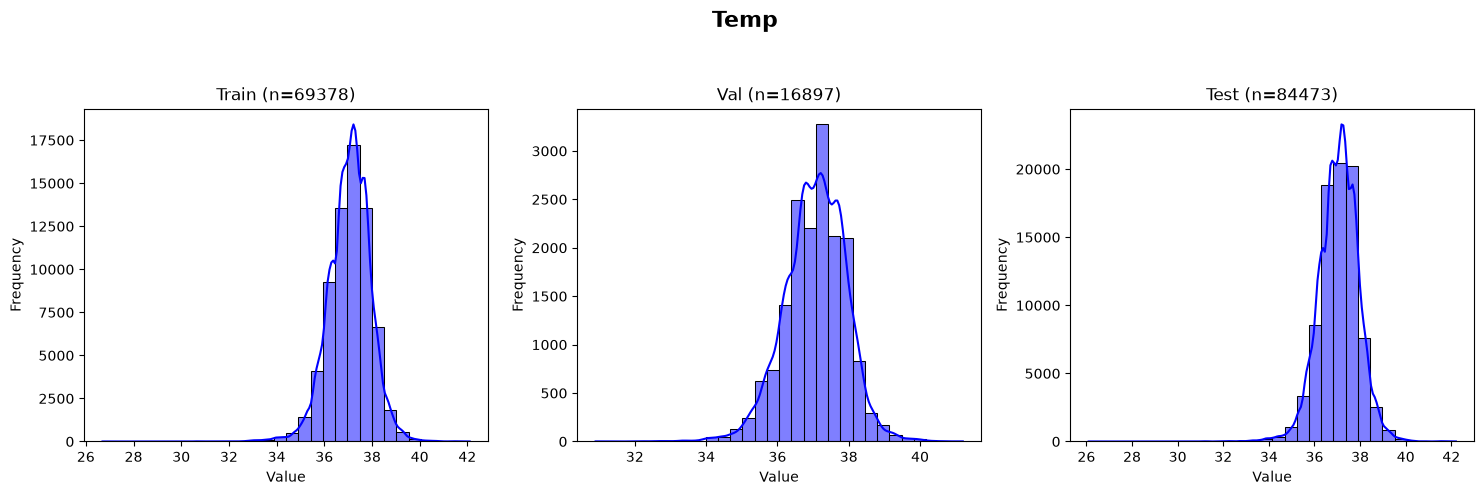

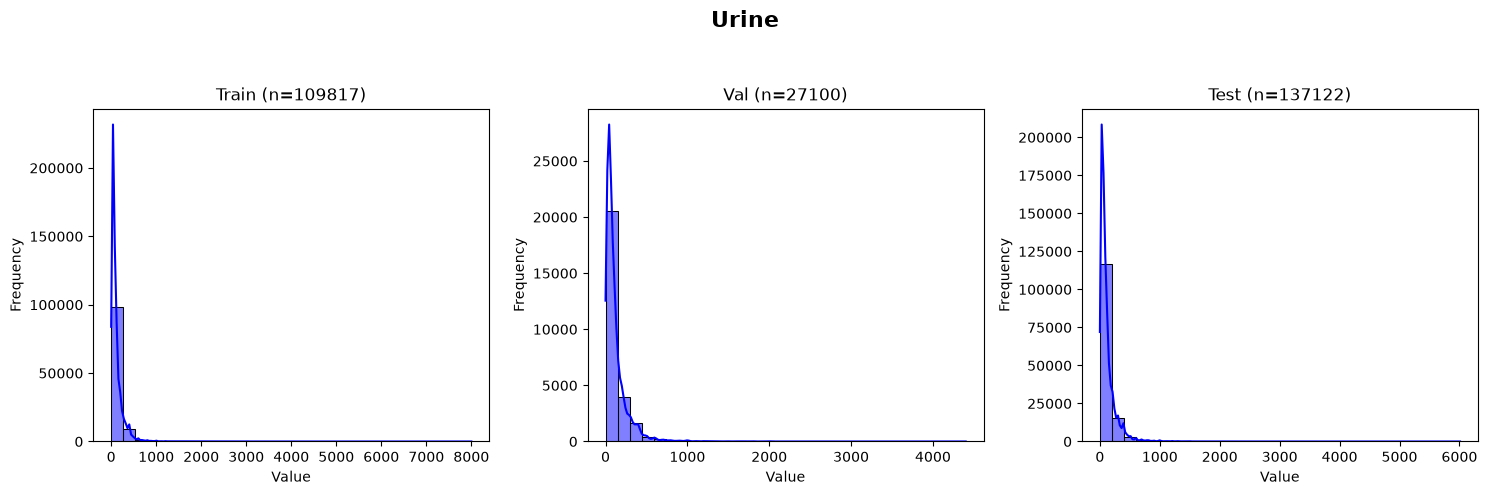

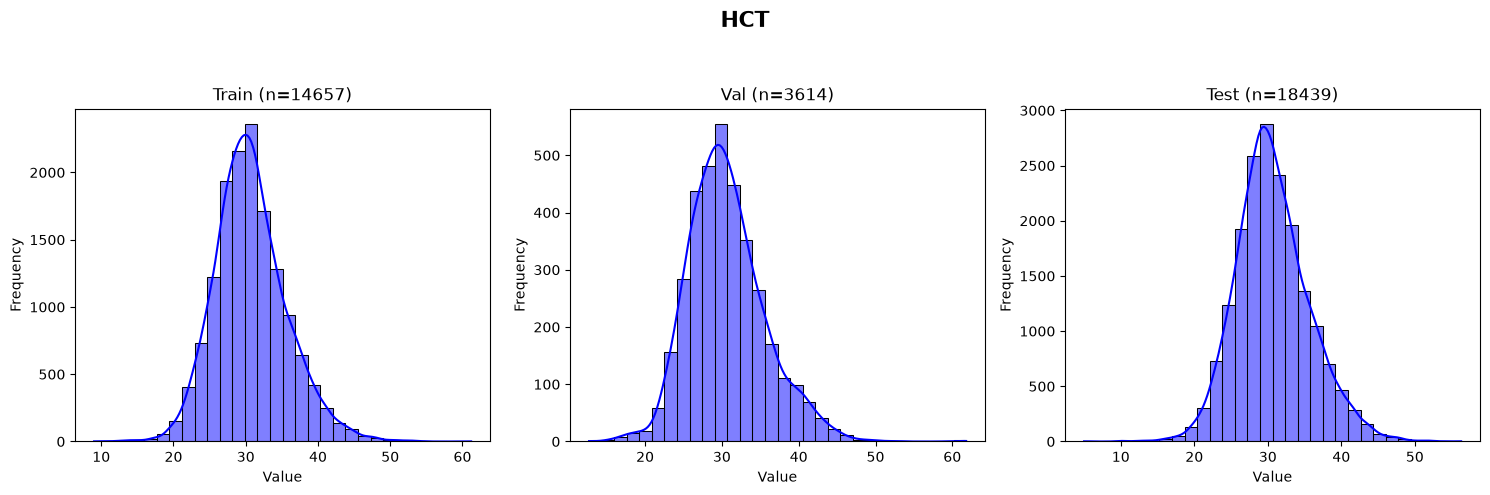

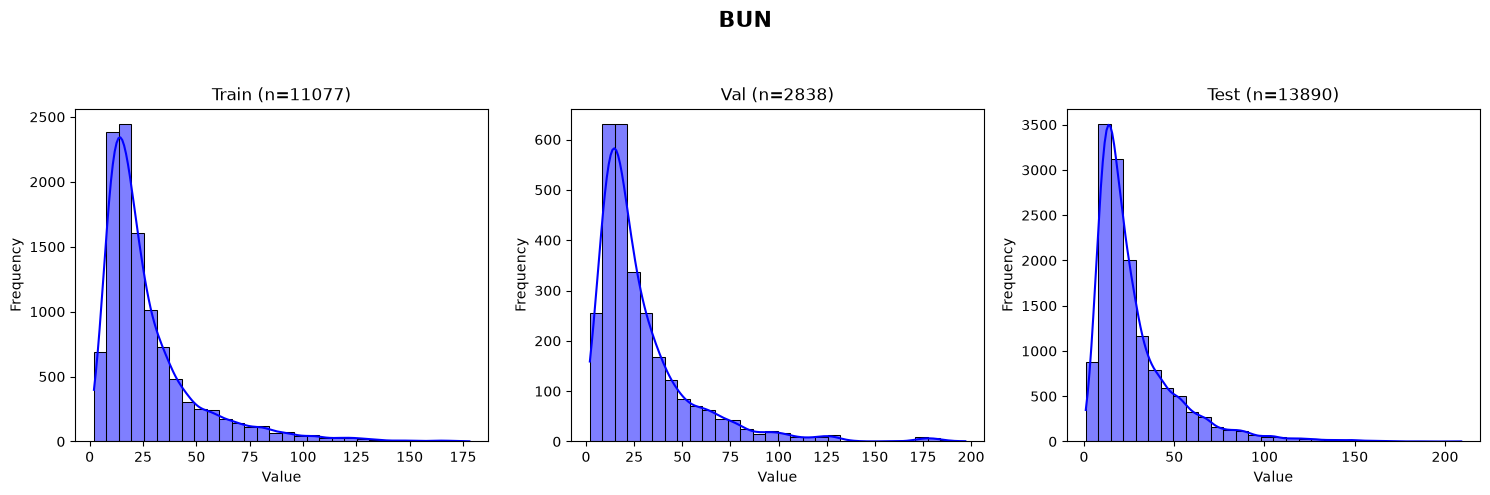

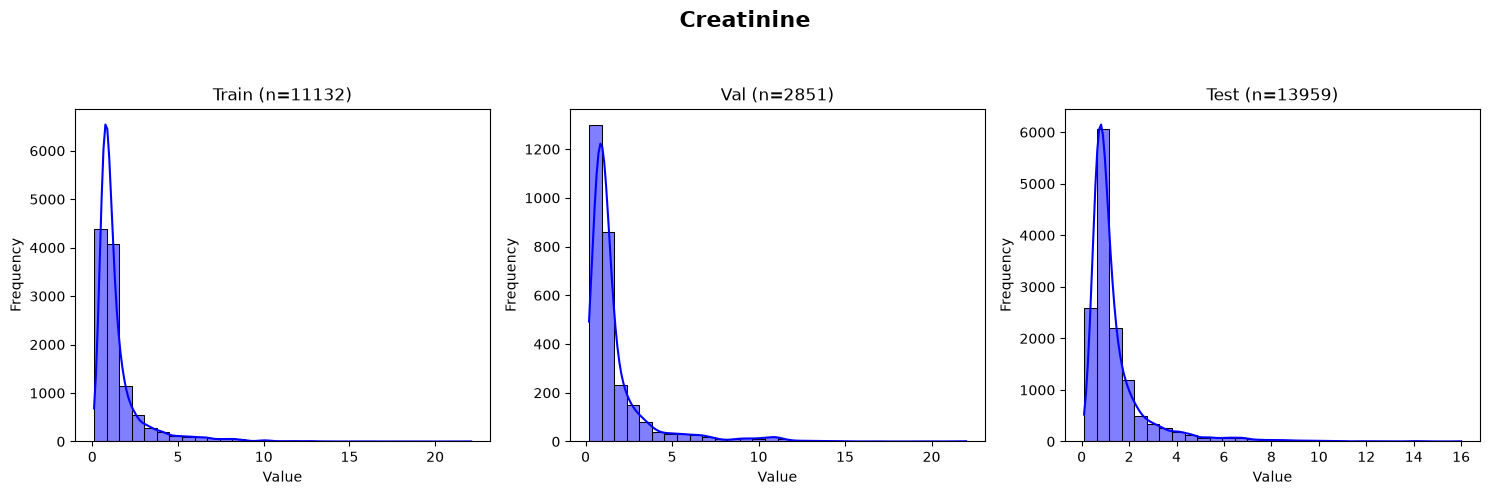

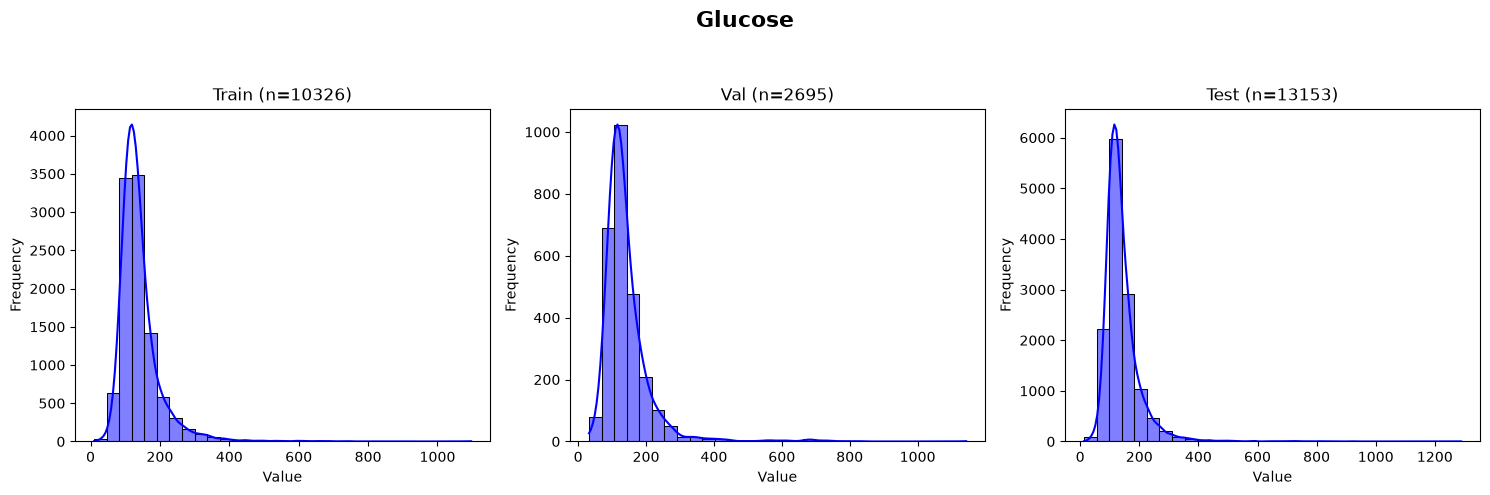

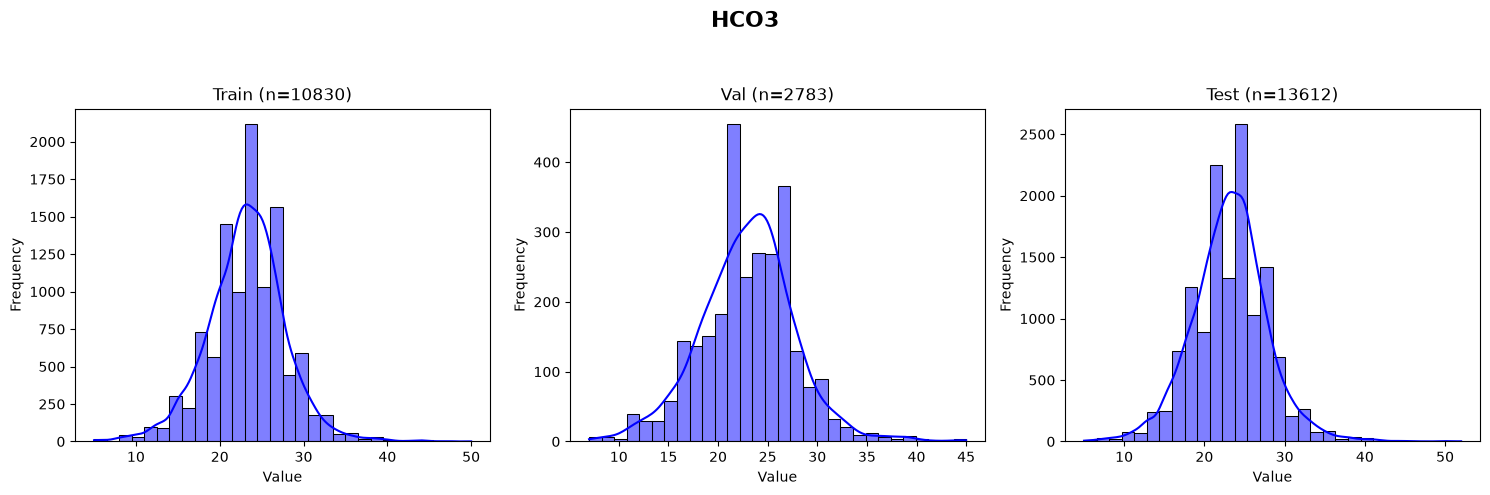

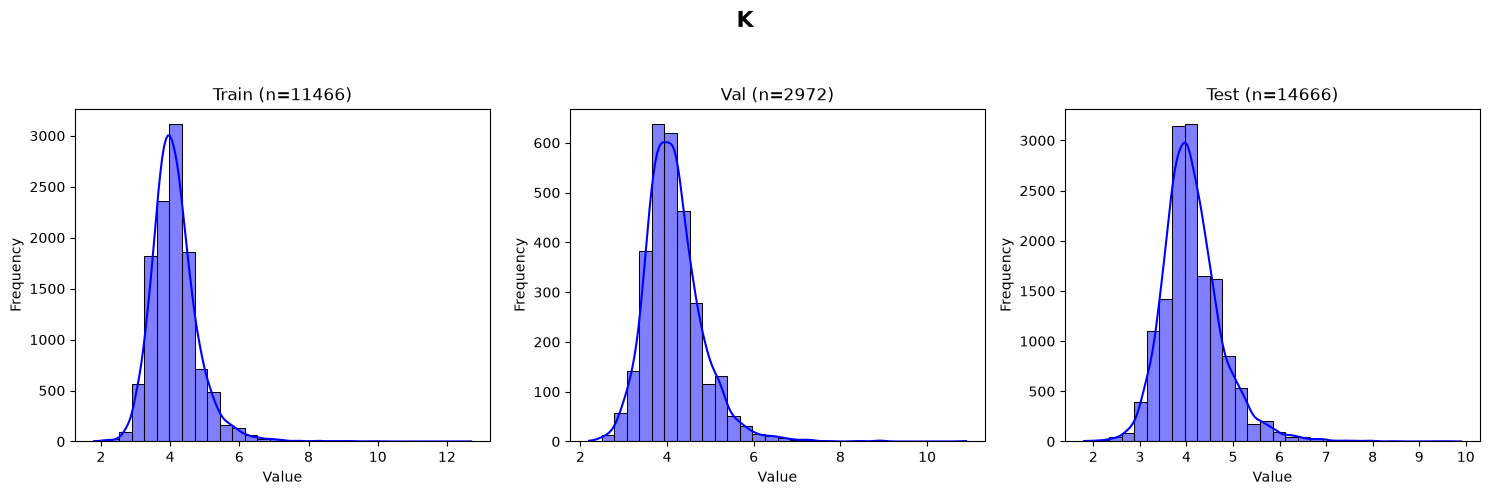

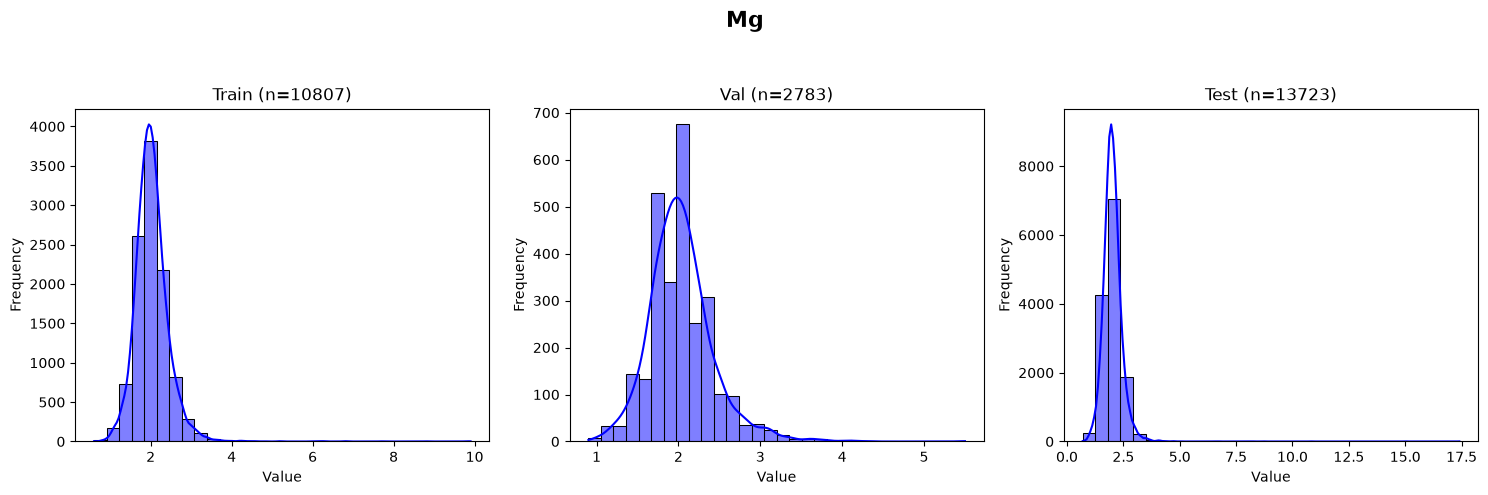

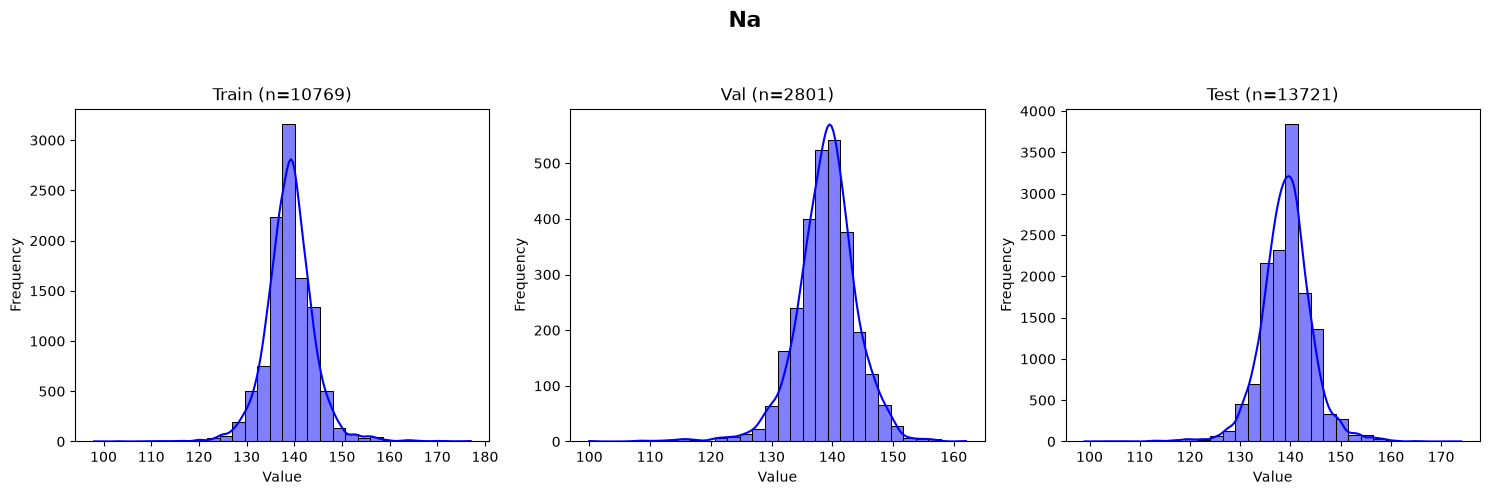

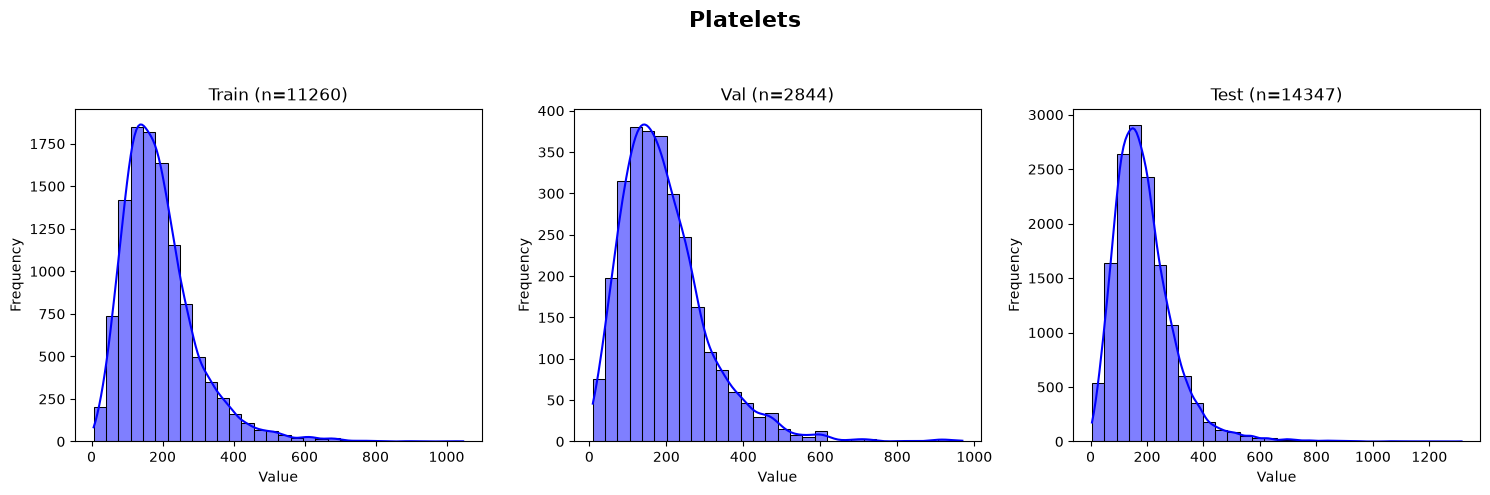

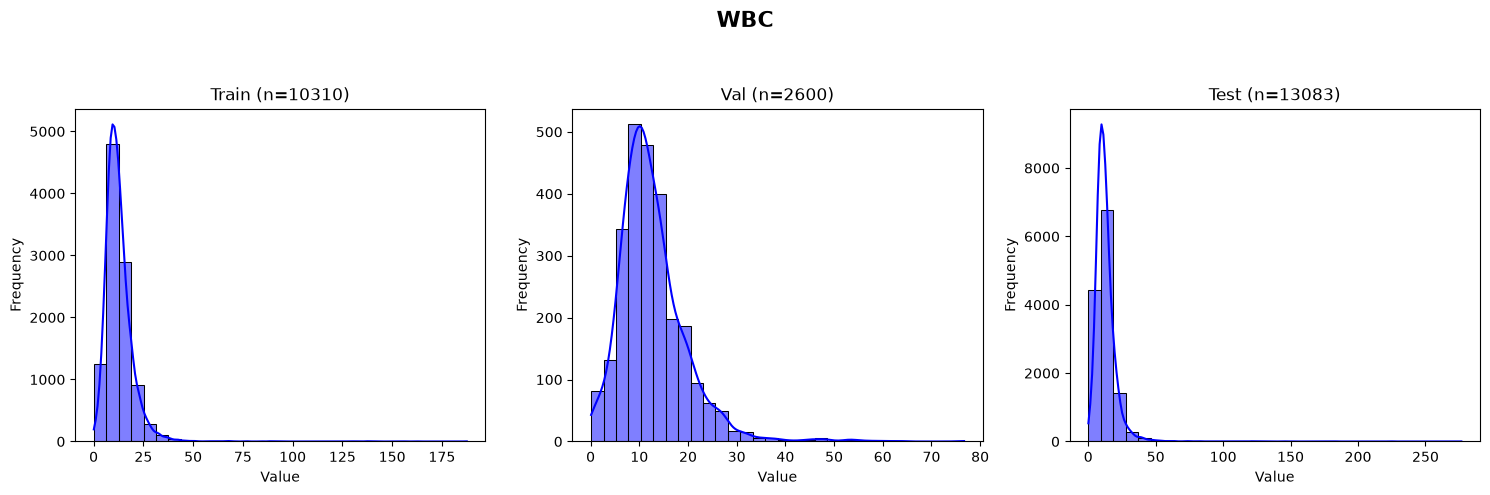

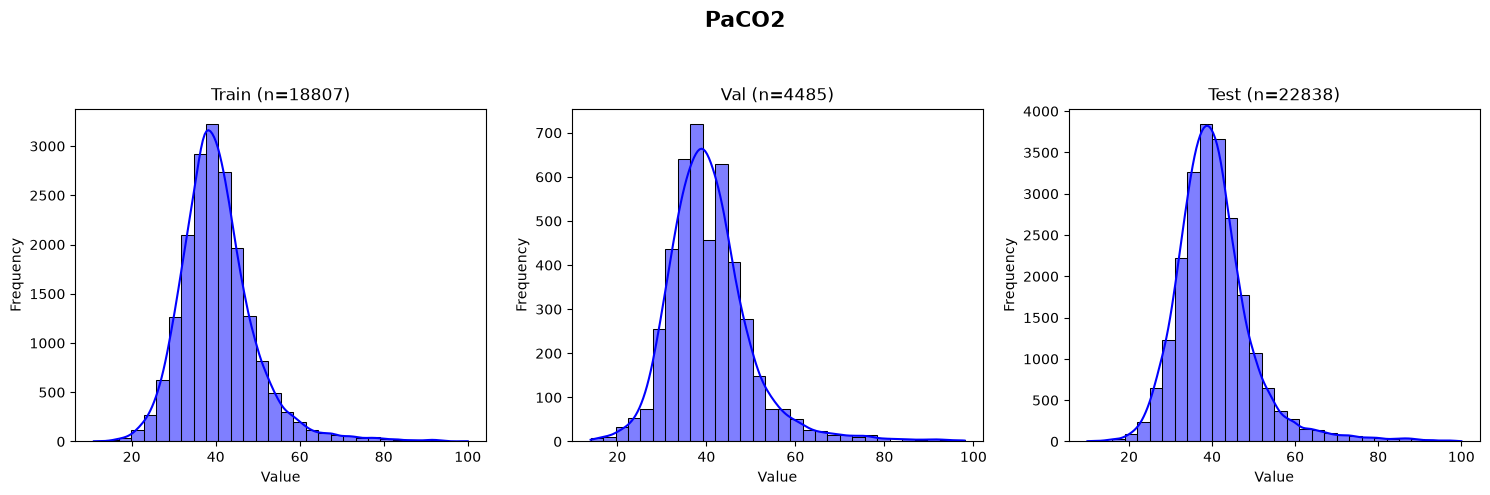

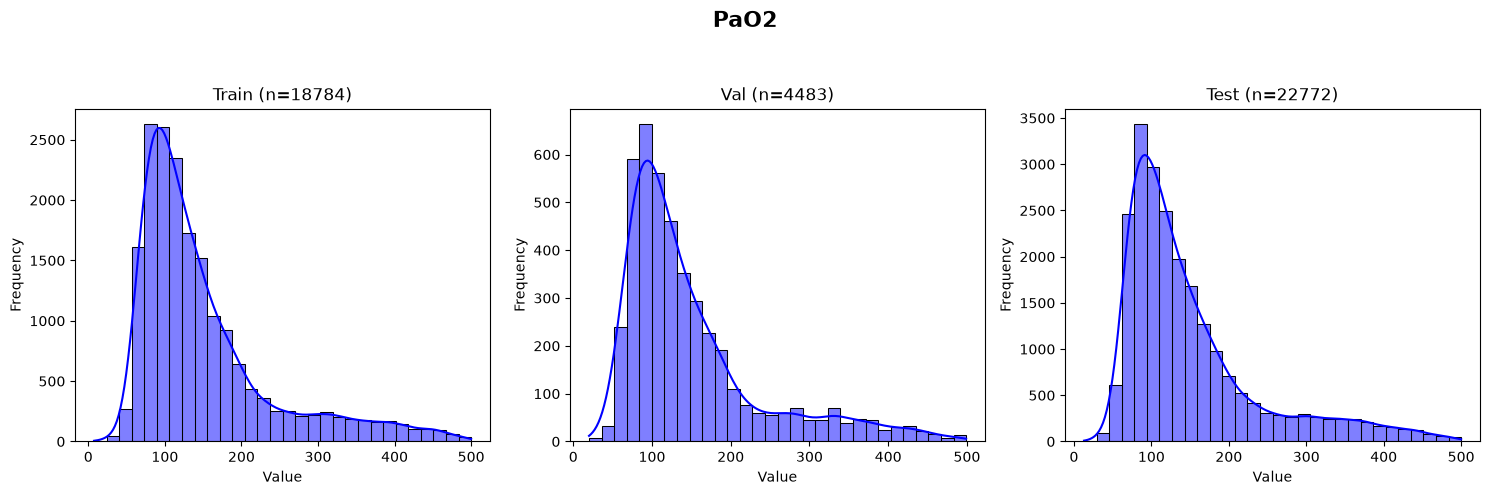

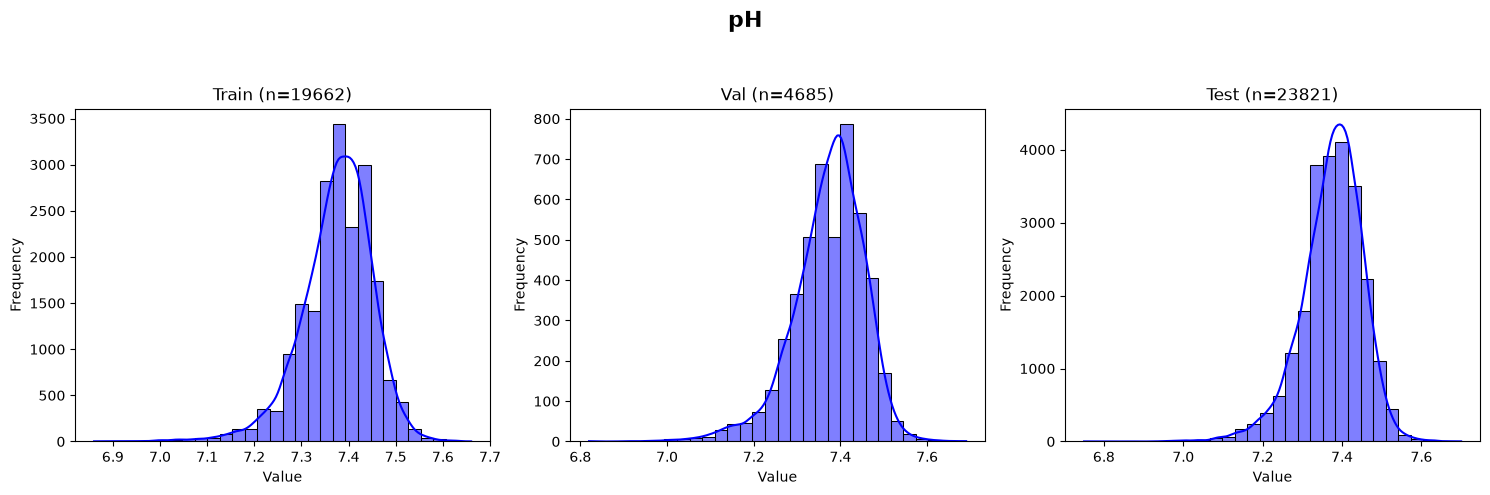

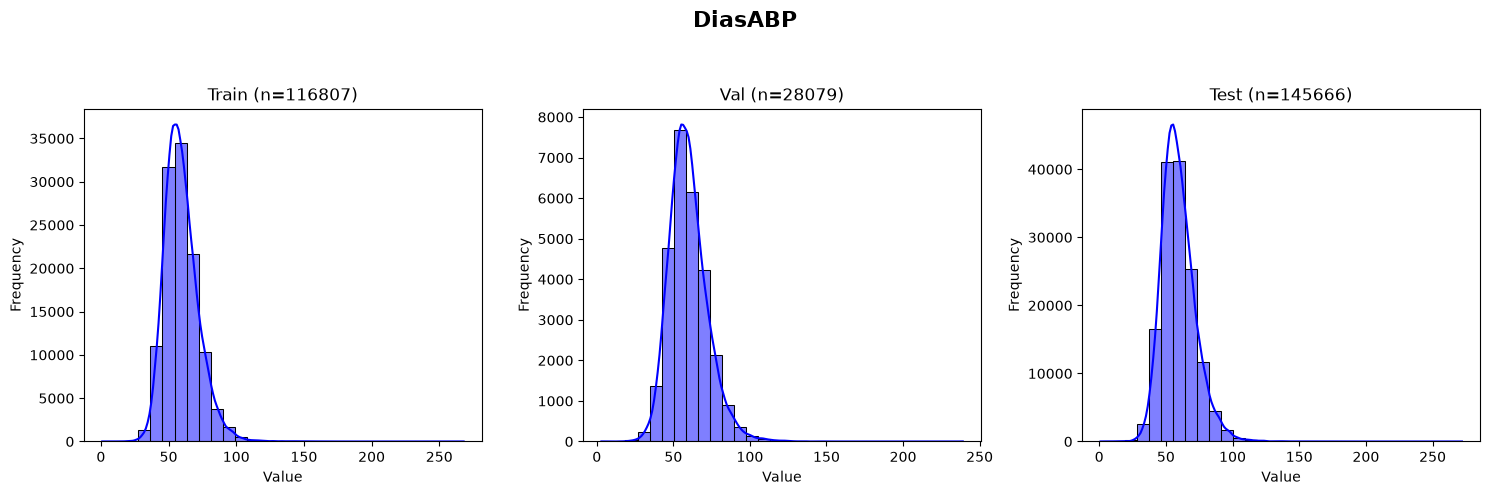

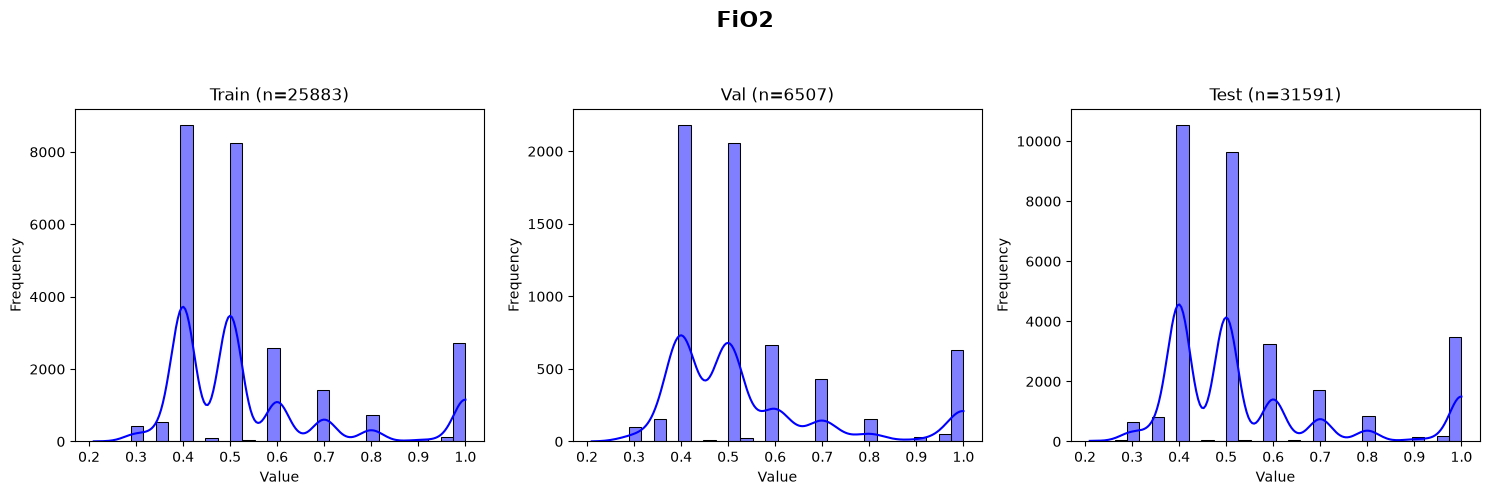

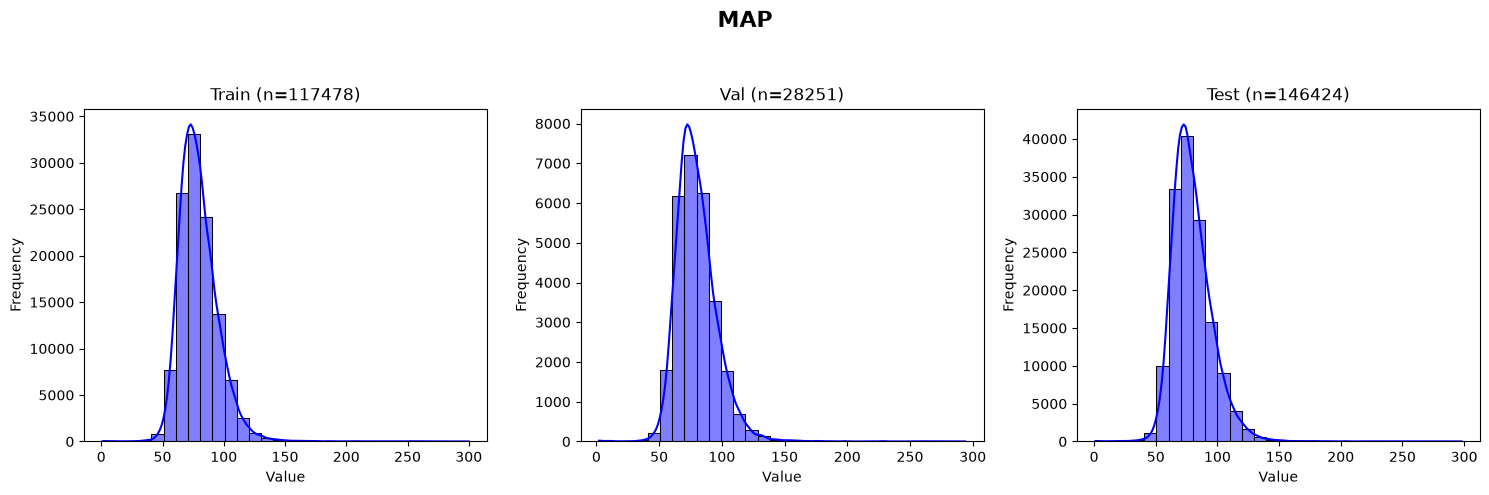

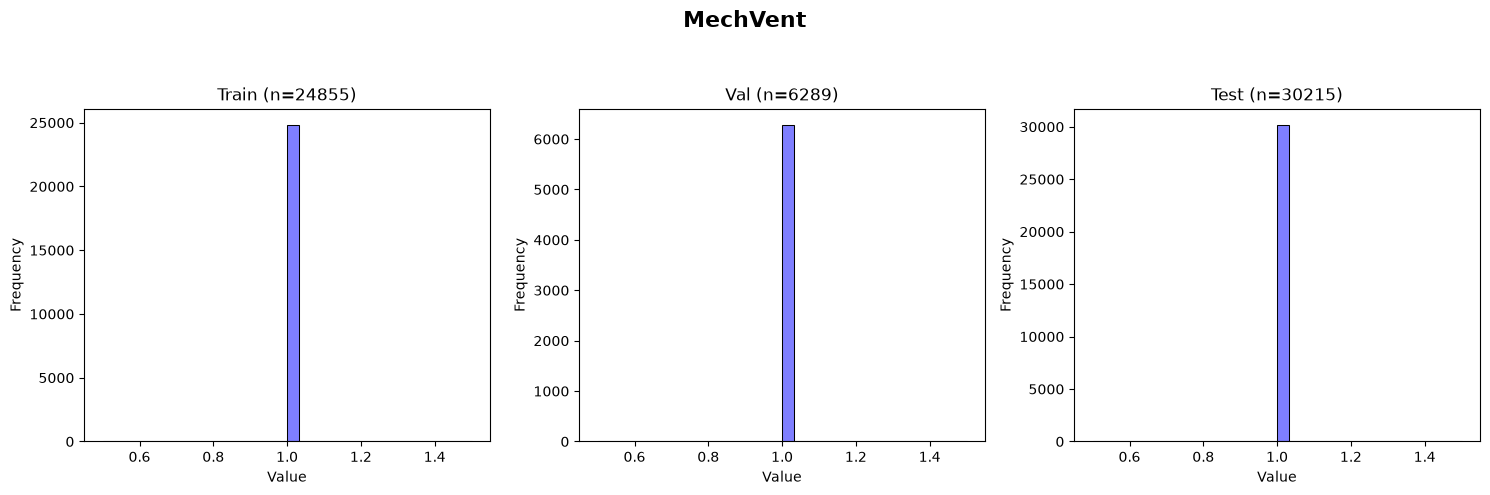

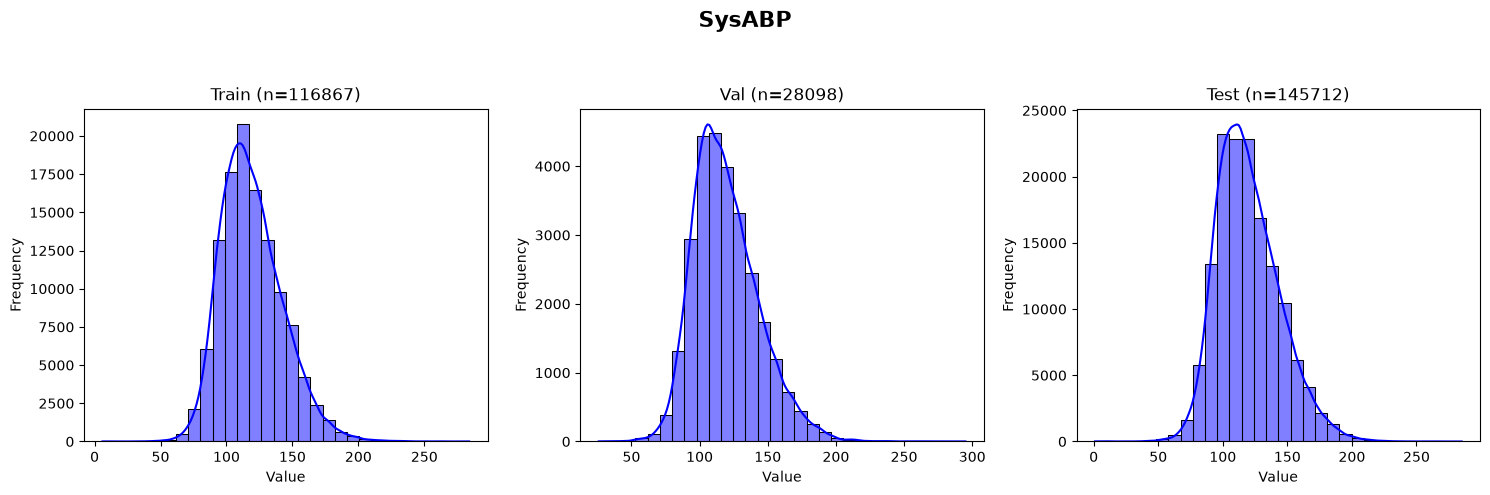

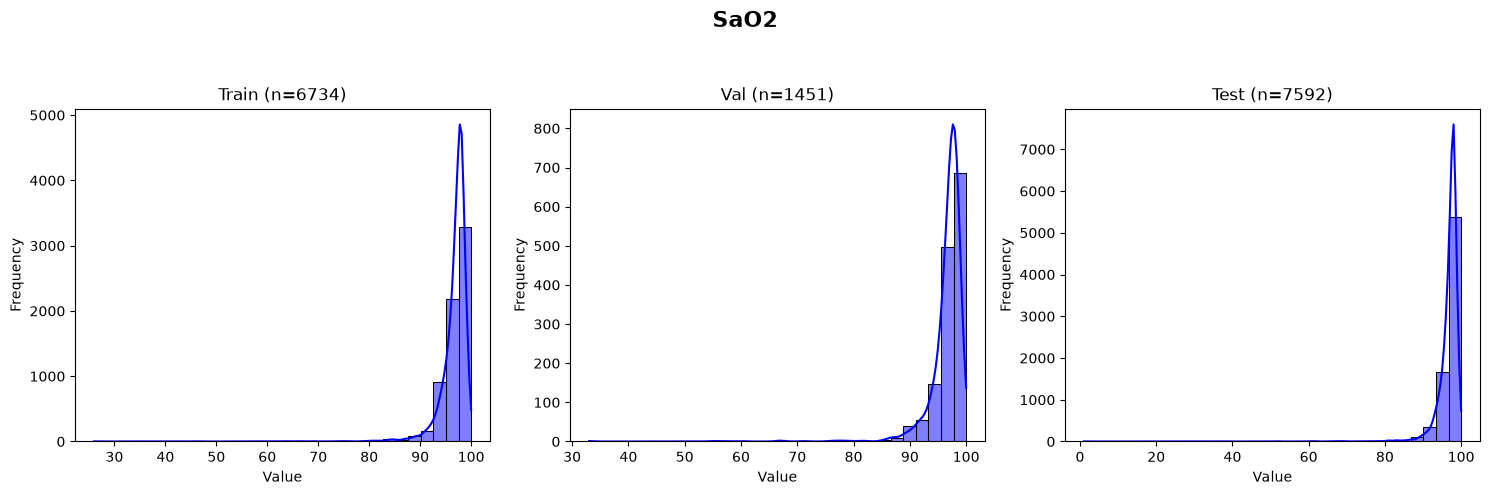

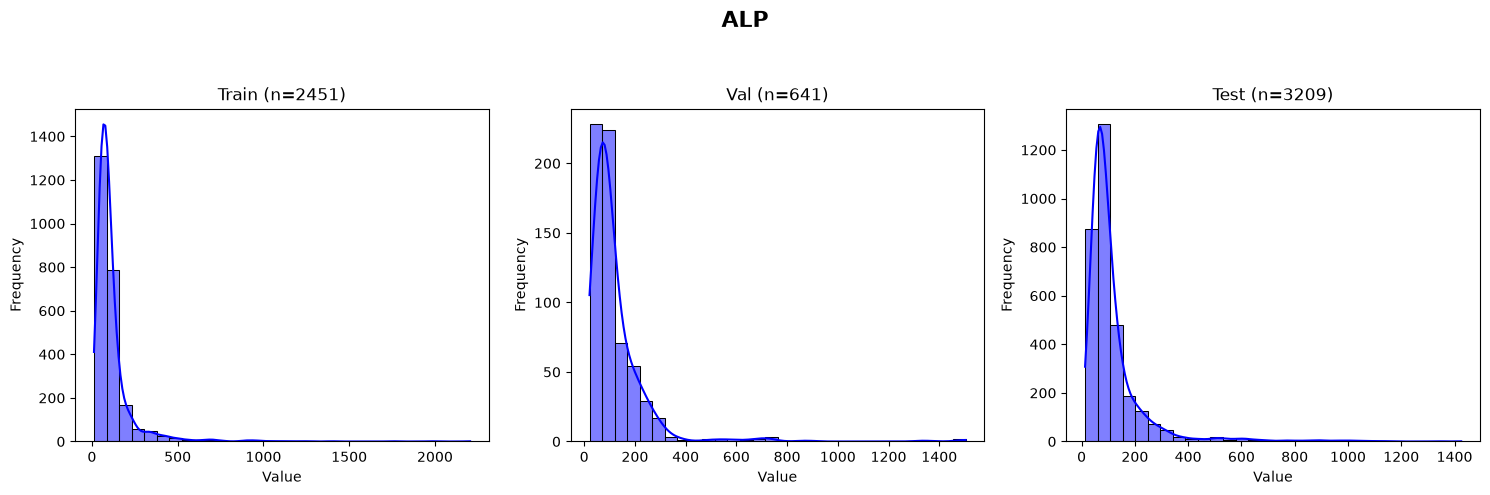

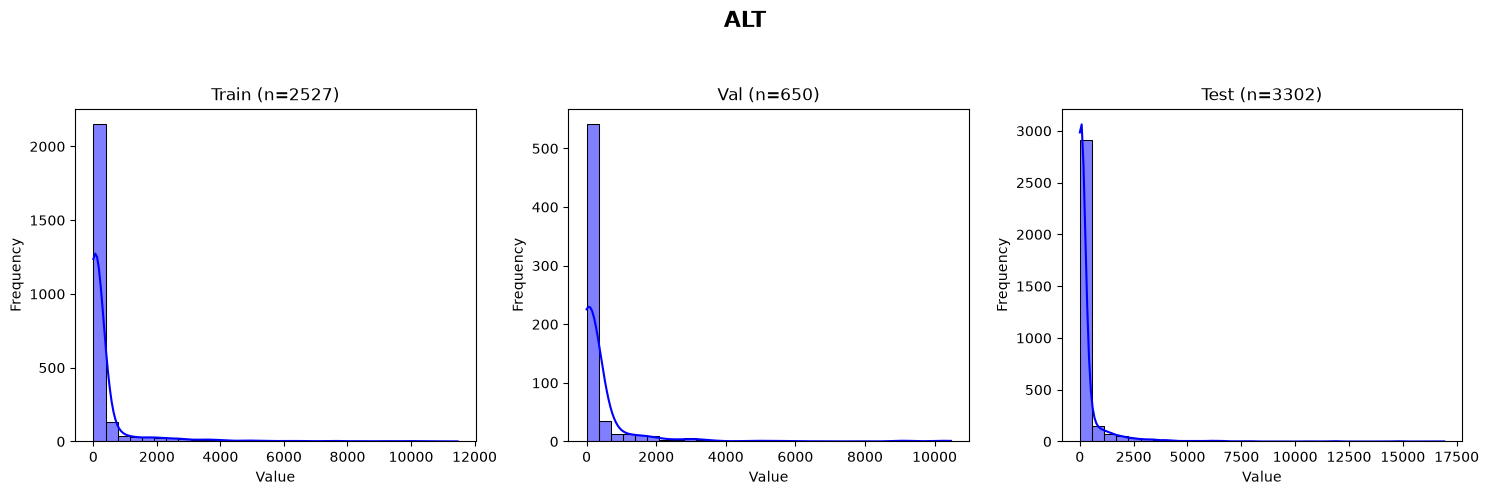

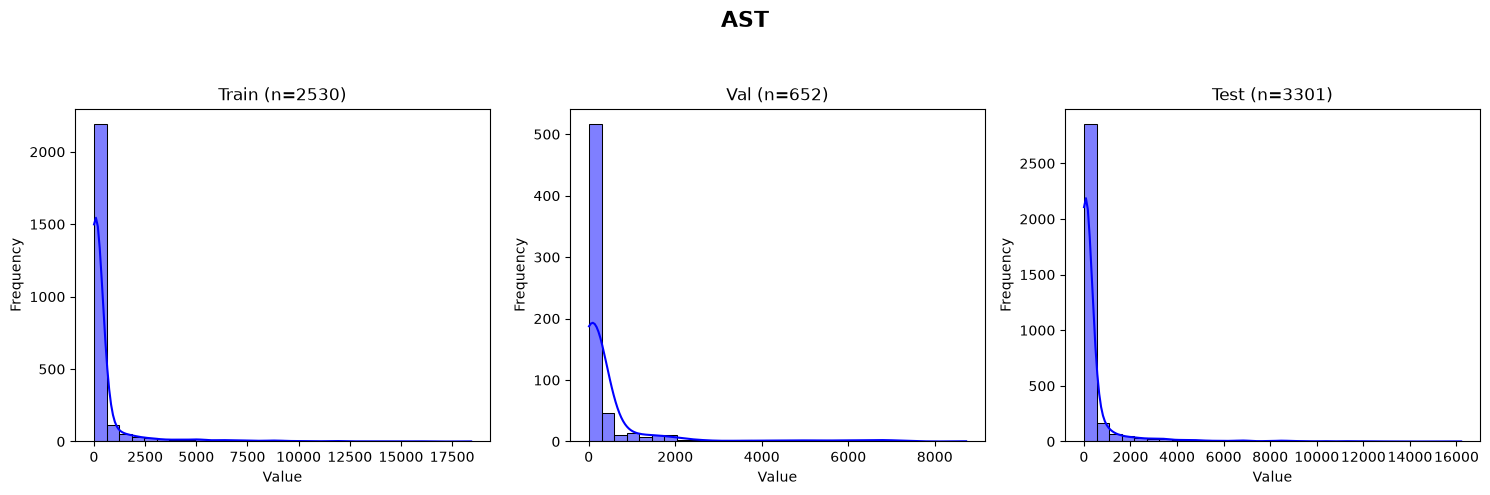

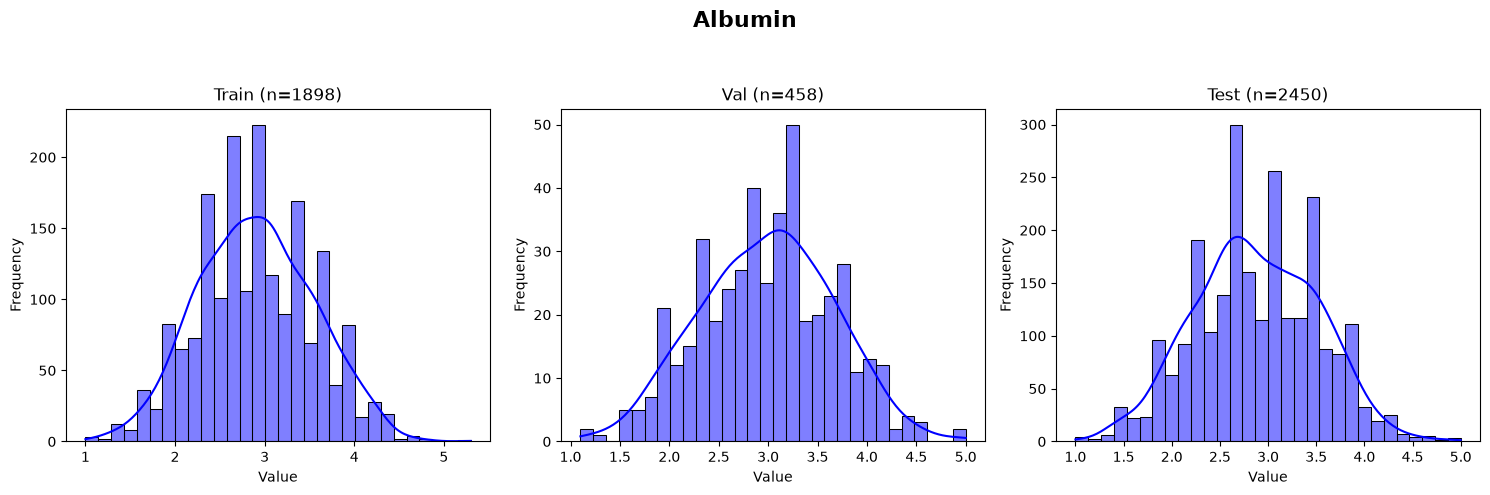

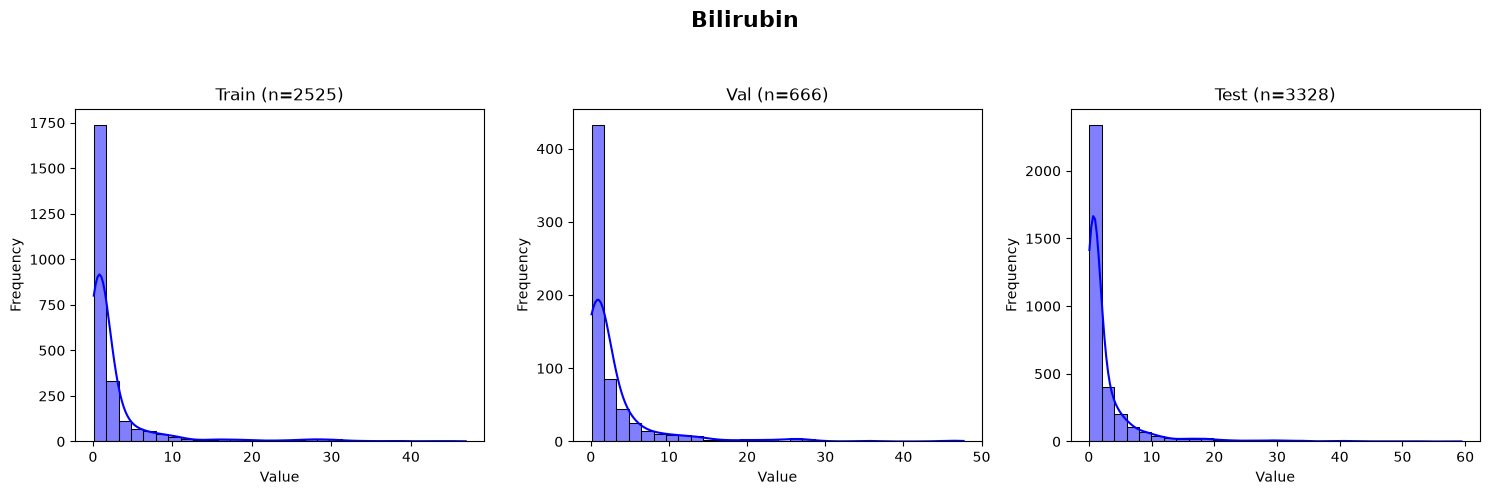

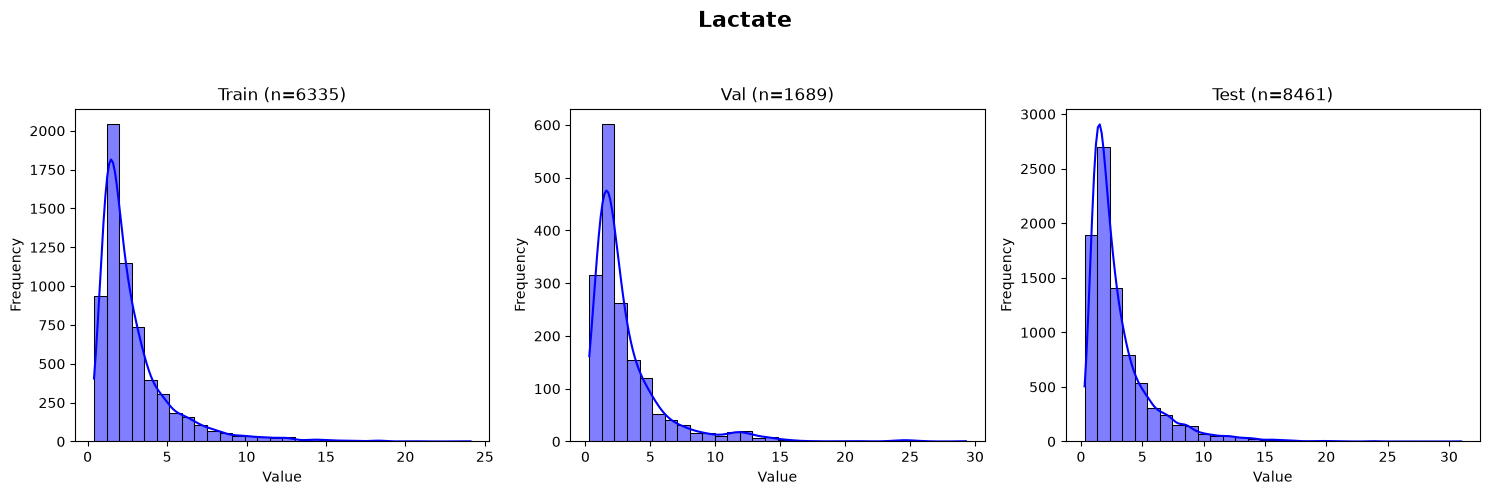

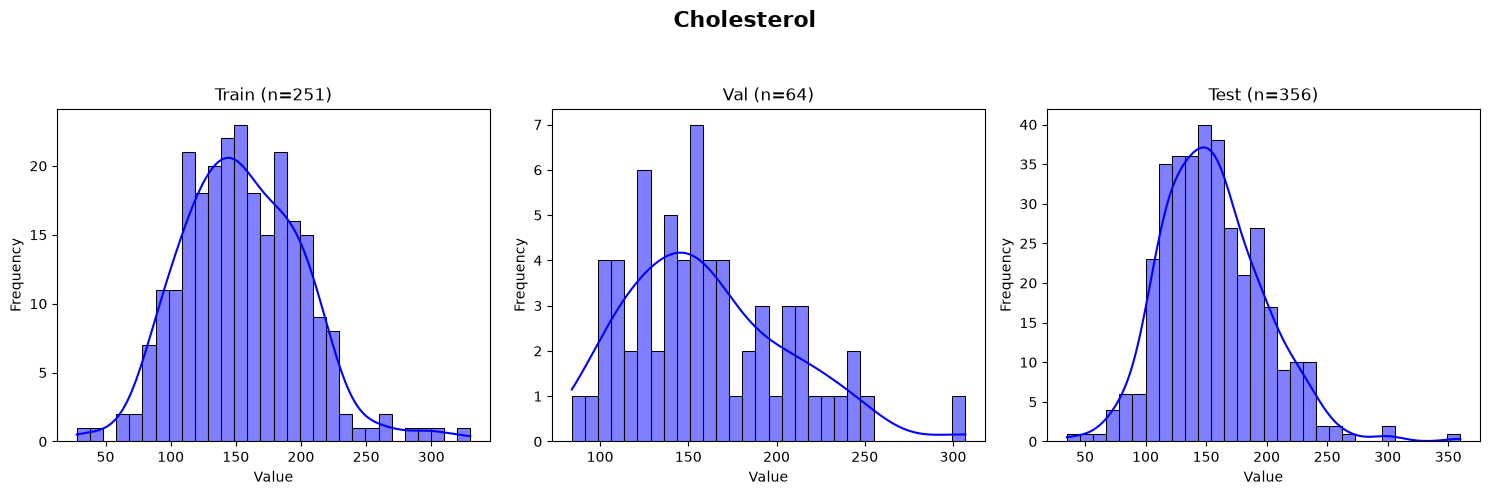

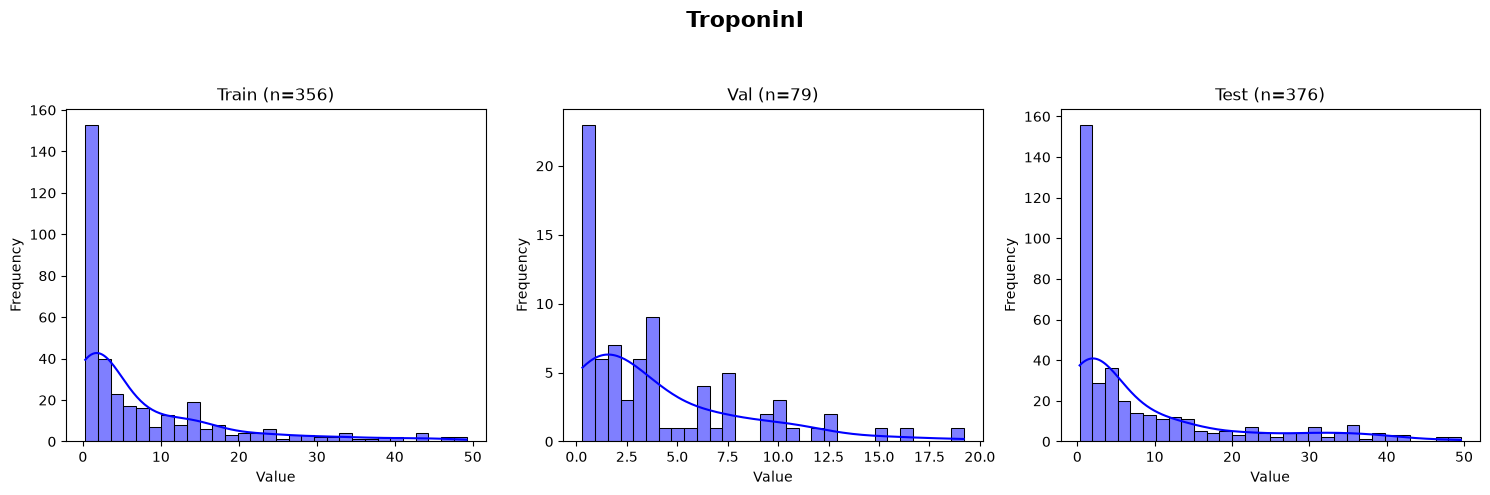

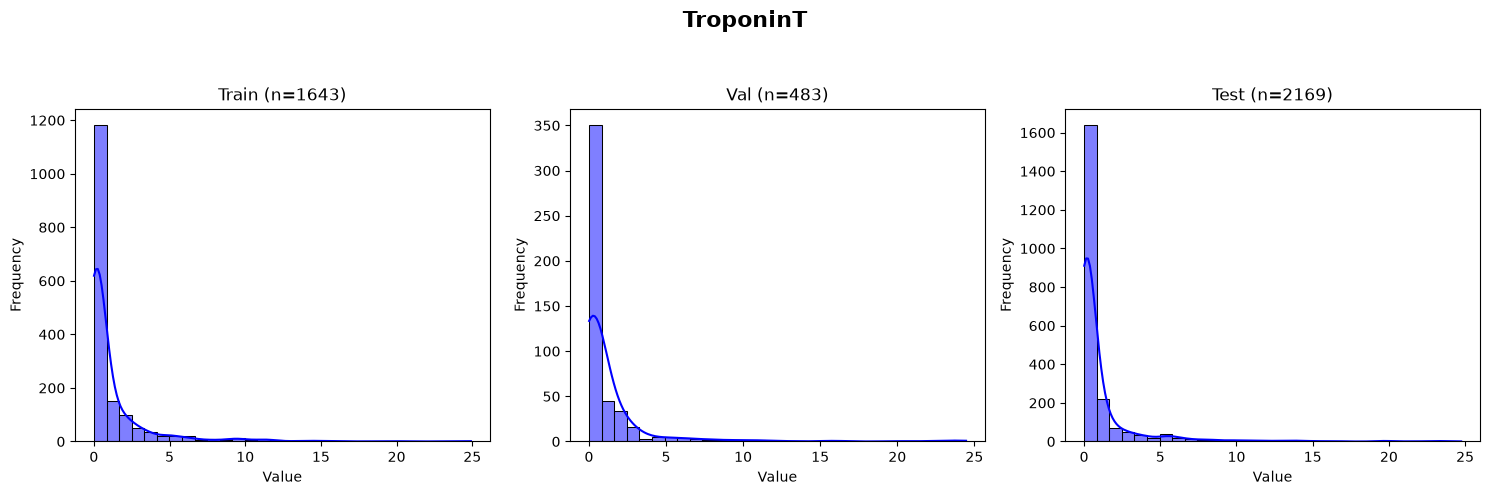

In [16]:
data_path = Path.cwd().parent /"data" 
datos = pd.read_csv(data_path / "processed/physionet2012.csv")

for var in datos["Variable"].dropna().unique():
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))

    for ax, split in zip(axs, ["train", "val", "test"]):
        values = datos.loc[
            (datos["Split"] == split) & (datos["Variable"] == var),
            "Value"
        ].dropna()

        sns.histplot(
            values,
            bins=30,
            alpha=0.5,
            color="blue",
            edgecolor="black",
            kde=True,
            ax=ax
        )

        ax.set_title(f"{split.capitalize()} (n={len(values)})")
        ax.set_xlabel("Value")
        ax.set_ylabel("Frequency")

    fig.suptitle(var, fontsize=16, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

In [17]:
# Crear encoder
enc = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

# Aplicar One Hot a ICUType
encoded = enc.fit_transform(datos[["ICUType"]])

# Convertir resultado a DataFrame
encoded_df = pd.DataFrame(
    encoded,
    columns=enc.get_feature_names_out(["ICUType"]),
    index=datos.index
)

# Eliminar ICUType original y añadir columnas codificadas
datos = pd.concat( [datos.drop(columns=["ICUType"]), encoded_df], axis=1)

train=datos[datos['Split']=='train']
val=datos[datos['Split']=='val']
test=datos[datos['Split']=='test']

In [18]:
datos.head()

,RecordID,Set,Split,Age,Gender,Height,Weight,In-hospital_death,SAPS-I,SOFA,Time,Variable,Value,ICUType_1,ICUType_2,ICUType_3,ICUType_4
0,132539,a,train,54.0,0.0,NaN,NaN,0,6.0,1.0,0.1167,GCS,15.00,0.0,0.0,0.0,1.0
1,132539,a,train,54.0,0.0,NaN,NaN,0,6.0,1.0,0.1167,HR,73.00,0.0,0.0,0.0,1.0
2,132539,a,train,54.0,0.0,NaN,NaN,0,6.0,1.0,0.1167,NIDiasABP,65.00,0.0,0.0,0.0,1.0
3,132539,a,train,54.0,0.0,NaN,NaN,0,6.0,1.0,0.1167,NIMAP,92.33,0.0,0.0,0.0,1.0
4,132539,a,train,54.0,0.0,NaN,NaN,0,6.0,1.0,0.1167,NISysABP,147.00,0.0,0.0,0.0,1.0


## Normalisation

Normalisation statistics are performed on the set training and then exported to val and test .

Each observed value is transformed per variable $v$ as

$$
\tilde x = \frac{g_v(x) - \mu_v}{\sigma_v}, \qquad
g_v(x) = \begin{cases} \log(1 + x) & \text{if } v \text{ is right-skewed} \\ x & \text{otherwise,} \end{cases}
$$

where $\mu_v$ and $\sigma_v$ are the mean and standard deviation of $g_v(x)$ over the training observations. 

The static vector contains Age, Gender, Height and Weight standardised with training statistics (0 when missing), missingness indicators for Gender, Height and Weight, and a one-hot encoding of ICUType.

In [19]:
skewness = train.groupby("Variable")["Value"].skew().dropna().reset_index(name="Value")
skewness['Skewness'] = skewness['Value'].apply(lambda x: True if abs(x) > 1 else False)

skewed = skewness[skewness['Skewness'] == True]
skewed_vars = skewed['Variable'].tolist()


In [20]:
from sklearn.preprocessing import StandardScaler, PowerTransformer

scalers = {}
transformers = {}

for var in datos['Variable'].unique():

    mask_var = datos['Variable'] == var
    mask_train = mask_var & (datos['Split'] == 'train')

    # Transformación de variables sesgadas
    if var in skewed_vars:
        pt = PowerTransformer(method="yeo-johnson", standardize=False)
        pt.fit(datos.loc[mask_train, 'Value'].values.reshape(-1, 1))
        datos.loc[mask_var, 'Value'] = pt.transform(datos.loc[mask_var, 'Value'].values.reshape(-1, 1)).ravel()

        transformers[var] = pt

    # Estandarización
    scaler = StandardScaler()
    scaler.fit(datos.loc[mask_train, 'Value'].values.reshape(-1, 1))
    datos.loc[mask_var, 'Value'] = scaler.transform(datos.loc[mask_var, 'Value'].values.reshape(-1, 1)).ravel()

    scalers[var] = scaler

In [21]:
datos.isna().sum()

RecordID                   0
Set                        0
Split                      0
Age                        0
Gender                  3046
Height               1387253
Weight                182775
In-hospital_death          0
SAPS-I                 80071
SOFA                   91413
Time                       0
Variable                   0
Value                      0
ICUType_1                  0
ICUType_2                  0
ICUType_3                  0
ICUType_4                  0
dtype: int64

In [22]:
datos["Gender"] = datos["Gender"].fillna(train["Gender"].mode()[0])
datos["Height"] = datos["Height"].fillna(train["Height"].mean())
datos["Weight"] = datos["Weight"].fillna(train["Weight"].mean())
datos=datos.drop(columns=['SOFA','SAPS-I'])
datos.to_csv(data_path / "processed/physionet2012_transformed.csv", index=False)
